## Setup

### Imports

In [2]:
import os
import itertools

import polars as pl
from matplotlib import pyplot as plt, patches, rcParams
import synapseclient

rcParams["font.family"] = "Arial"

### Constants

In [3]:
# Jupyter server should be running from src/python
# assumes auth_token.txt exists in src/python as described in setup instructions
AUTH_TOKEN = os.path.abspath("auth_token.txt")

# cached metadata table, apache arrow format, on synapse 
META_CACHE_SYNID = "syn74775994"

# Jupyter server should be running from src/python
FIGURE_DIR = os.path.join(
    os.path.dirname(os.path.dirname(os.getcwd())),
    "analysis",
    "mutations",
    "_figures"
)

In [4]:
# ensure the figures directory exists
os.makedirs(FIGURE_DIR, exist_ok=True)

### Synapse Login

In [5]:
with open(AUTH_TOKEN, "r") as atf:
    SYN = synapseclient.login(authToken=atf.read())


UPGRADE AVAILABLE

A more recent version of the Synapse Client (4.14.0) is available. Your version (4.11.0) can be upgraded by typing:
   pip install --upgrade synapseclient

Python Synapse Client version 4.14.0 release notes

https://python-docs.synapse.org/news/


Welcome, dylan.ross!



### Load metadata from cached file
(fetch from synapse)

In [6]:
meta = pl.read_ipc(SYN.get(META_CACHE_SYNID).path)
meta

[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_57076/1558984119.py:1: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  meta = pl.read_ipc(SYN.get(META_CACHE_SYNID).path)



[syn74775994:metadata.arrow]: Found existing file at /Users/dylan.ross/Projects/AML_outcome_disparities/261016_diffex_overview/diffex_overview/aml_outcome_disparities/analysis/mutations/_cache/metadata.arrow, skipping download.


Sample,Age,Sex,Race,Study,FLT3_ITD,NPM1,DNMT3A
str,f64,str,str,str,bool,bool,bool
"""11-00261""",74.0,"""Male""","""White""","""BeatAML""",true,false,false
"""11-00503""",54.0,"""Female""","""White""","""BeatAML""",true,true,false
"""11-00475""",65.0,"""Male""","""White""","""BeatAML""",true,true,false
"""12-00032""",70.0,"""Male""","""White""","""BeatAML""",true,false,false
"""11-00376""",49.0,"""Male""","""White""","""BeatAML""",true,true,false
…,…,…,…,…,…,…,…
"""16-01109-Bridge""",33.0,"""Male""","""Black""","""pilotStudy""",false,false,false
"""16-01191-Bridge""",65.0,"""Female""","""White""","""pilotStudy""",false,false,false
"""17-00025-Bridge""",39.0,"""Female""","""White""","""pilotStudy""",true,true,true


## Analysis

### Summary UpSet Plot

In [9]:
def _count_samples(
    race,
    mut,
):
    # filter metadata by race 
    _meta = meta.filter(pl.col("Race") == race)
    # filter metadata by mutations
    match mut:
        case "WT":
            _meta = _meta.filter(
                ~pl.col("NPM1")
                & ~pl.col("FLT3_ITD")
                & ~pl.col("DNMT3A")
            )
        case "NPM1":
            _meta = _meta.filter(
                pl.col("NPM1")
                & ~pl.col("FLT3_ITD")
                & ~pl.col("DNMT3A")
            )
        case "FLT3-ITD": 
            _meta = _meta.filter(
                ~pl.col("NPM1")
                & pl.col("FLT3_ITD")
                & ~pl.col("DNMT3A")
            )
        case "DNMT3A": 
            _meta = _meta.filter(
                ~pl.col("NPM1")
                & ~pl.col("FLT3_ITD")
                & pl.col("DNMT3A")
            )
        case "NPM1xFLT3-ITD":
            _meta = _meta.filter(
                pl.col("NPM1")
                & pl.col("FLT3_ITD")
                & ~pl.col("DNMT3A")
            )
        case "NPM1xDNMT3A":
            _meta = _meta.filter(
                pl.col("NPM1")
                & ~pl.col("FLT3_ITD")
                & pl.col("DNMT3A")
            )
        case "FLT3-ITDxDNMT3A":
            _meta = _meta.filter(
                ~pl.col("NPM1")
                & pl.col("FLT3_ITD")
                & pl.col("DNMT3A")
            )
        case "NPM1xFLT3-ITDxDNMT3A":
            _meta = _meta.filter(
                pl.col("NPM1")
                & pl.col("FLT3_ITD")
                & pl.col("DNMT3A")
            )
        case _:
            assert False
    return len(_meta)


# key: (race label, mutation label)
# value: (sample count)
sample_counts = {
    (race == "Black", mut): _count_samples(race, mut)
    for race in ["White", "Black"]
    for mut in [
        "WT", 
        "NPM1", "FLT3-ITD", "DNMT3A",
        "NPM1xFLT3-ITD", "NPM1xDNMT3A", "FLT3-ITDxDNMT3A",
        "NPM1xFLT3-ITDxDNMT3A"
    ]
}

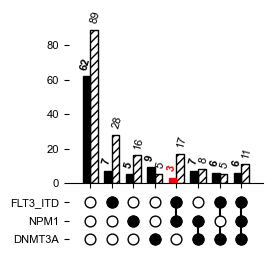

In [22]:
# --- setup ---

# figure and subpanels
fig, (ax_topbars, ax_combo_dots) = plt.subplots(
    nrows=2,
    height_ratios=(2.5, 1),
    figsize=(2.5, 3.),
    gridspec_kw={"hspace": 0.05}
)

# max font size 
rcParams["font.size"] = 8

# colors
c_white = "w"
c_black = "k"
c_border = c_black

# misc parameters
w = 0.35            # bar width
lw = 1.             # line width for borders
r = 0.15             # circle radius
hatch = "////"      # hatching for white bars
split_y = False     # split the y-axis in the top bar plot
count_pad = 3       # pad the counts up from the tops of the bars by a bit

# key: mutation name
# value: y-index in upset plot
mut_to_y = {
    "FLT3_ITD": 0.9,
    "NPM1": 0.5,
    "DNMT3A": 0.1
}

# add a separate y axis for white and black groups
# black is main y axis white is secondary y axis
# only if split_y flag is set
ax_ne2 = ax_topbars.twinx() if split_y else ax_topbars


# --- plot the data ---

xfactor = 1
mut_to_x = {
    "WT": 1,
    "FLT3-ITD": 2,
    "NPM1": 3,
    "DNMT3A": 4,
    "NPM1xFLT3-ITD": 5,
    "NPM1xDNMT3A": 6,
    "FLT3-ITDxDNMT3A": 7,
    "NPM1xFLT3-ITDxDNMT3A": 8
}
mut_to_ys = {
    "WT": [],
    "FLT3-ITD": [mut_to_y["FLT3_ITD"]],
    "NPM1": [mut_to_y["NPM1"]],
    "DNMT3A": [mut_to_y["DNMT3A"]],
    "NPM1xFLT3-ITD": [mut_to_y["NPM1"], mut_to_y["FLT3_ITD"]],
    "NPM1xDNMT3A": [mut_to_y["NPM1"], mut_to_y["DNMT3A"]],
    "FLT3-ITDxDNMT3A": [mut_to_y["FLT3_ITD"], mut_to_y["DNMT3A"]],
    "NPM1xFLT3-ITDxDNMT3A": [mut_to_y["NPM1"], mut_to_y["FLT3_ITD"], mut_to_y["DNMT3A"]],
}
mut_to_line_y1y2 = {
    "NPM1xFLT3-ITD": (mut_to_y["NPM1"], mut_to_y["FLT3_ITD"]),
    "NPM1xDNMT3A": (mut_to_y["NPM1"], mut_to_y["DNMT3A"]),
    "FLT3-ITDxDNMT3A": (mut_to_y["DNMT3A"], mut_to_y["FLT3_ITD"]),
    "NPM1xFLT3-ITDxDNMT3A": (mut_to_y["DNMT3A"], mut_to_y["FLT3_ITD"]),
}

# iterate through all combinations of mutations from lowest to highest
# fill in the top bars and bottom dots
for (black, mut), count in sample_counts.items():
    x = mut_to_x[mut]
    # black bars
    if black:
        ax_topbars.bar(
            [x], 
            [count],
            width=-w,  # align to right edge
            align="edge",
            facecolor=c_black if count >= 5 else "#F00",
            edgecolor=c_border if count >= 5 else "#F00",
            linewidth=lw,
        )
    else:
        ax_ne2.bar(
            [x], 
            [count], 
            width=w,  # align to left edge
            align="edge",
            facecolor=c_white,
            edgecolor=c_border if count >= 5 else "#F00",
            linewidth=lw,
            hatch=hatch
        )

    # label each bar with the count (if count > 0)
    if black: 
        ax_topbars.text(
            x - w / 1.5,
            count + count_pad,
            count,
            va="bottom",
            ha="center",
            rotation=75,
            fontsize=8, 
            fontweight="bold",
            color=c_black if count >= 5 else "#F00",
        )
    else: 
        ax_ne2.text(
            x + w / 1.5,
            count + count_pad,
            count,
            va="bottom",
            ha="center",
            rotation=75,
            fontsize=8,
            color=c_black if count >= 5 else "#F00",
        )

    # dots
    if black:
        if (y1y2 := mut_to_line_y1y2.get(mut)) is not None:
            ax_combo_dots.plot(
                [x, x], 
                [y1y2[0], y1y2[1]], 
                "k-", 
                lw=1.5,
                zorder=-1
            )
        for y in mut_to_y.values():
            ax_combo_dots.scatter(
                x, y,
                s=60, 
                facecolor="w", 
                edgecolor=c_border, 
                linewidth=lw, 
                zorder=2
            ) 
        for y in mut_to_ys[mut]:
            ax_combo_dots.scatter(
                x, y,
                s=60, 
                facecolor="k", 
                edgecolor=c_border, 
                linewidth=lw, 
                zorder=2
            )   

# --- customization ---

# top bars
ax_topbars.set_xticks(range(1, x + 1))
ax_topbars.set_xlim((0, x + 1))
ax_topbars.set_xticklabels([])
for d in ["top", "right", "left"]:
    ax_topbars.spines[d].set_visible(False)
if split_y:
    # only perform this additional customization if we split the y axis
    ax_topbars.set_ylabel("Black")
    ax_ne2.set_ylabel("White")
    ax_ne2.set_xticklabels([])
    ax_ne2.set_xlim((0, x + 1))
    ax_ne2.set_xticks(range(1, x + 1))
    ax_ne2.set_yticks([])
    for d in ["top", "left", "right"]:
        ax_ne2.spines[d].set_visible(False)

# combo dots
ax_combo_dots.set_xlim((0, x + 1))
ax_combo_dots.set_xticks([])
ax_combo_dots.set_ylim((-0.2, 1.2))
ytl = ["FLT3_ITD", "NPM1", "DNMT3A"]
ax_combo_dots.set_yticks([mut_to_y[_] for _ in ytl])
ax_combo_dots.set_yticklabels(["FLT3_ITD", "NPM1", "DNMT3A"])
for d in ["top", "right", "bottom", "left"]:
    ax_combo_dots.spines[d].set_visible(False)
#ax_combo_dots.set_aspect("equal")


# --- finish ---
#plt.tight_layout()
#plt.subplots_adjust(wspace=0, hspace=0)
plt.savefig(
    os.path.join(FIGURE_DIR, "mutations_upset_race-stratified.pdf"),
    bbox_inches="tight",
)
plt.show()
plt.close()